# 239. Sliding Window Maximum
**Difficulty:** 🔴 Hard · **Topic:** Sliding Window · **Pattern:** [Fixed Window](README.md) · **LeetCode:** https://leetcode.com/problems/sliding-window-maximum/

## 💡 Concepts

**Core concept(s):** **fixed-size sliding window** + **monotonic deque**.

**Why it applies here:**
- Every window has the same width `k`, and each step right adds one number and drops one number: the fixed-window shape.
- A running **sum** is easy to update when a number leaves (subtract it). A running **max** is not: if the max leaves, you don't know the next-largest. So the window needs a smarter summary than one number.
- A number that is **older and not bigger** than a newer number can never be a window max again: the newer one outlives it and beats it. Throw it away. What remains is decreasing.

**Key intuition:**
- Keep a deque of **indices** whose values are strictly decreasing from front to back.
- The **front** is always the max of the current window.
- New number: pop smaller-or-equal numbers off the **back**, then push it. Old index leaving the window: pop it off the **front** if it is still there.

---

### 📚 What is a Sliding Window (fixed size)?
- A **window** is a contiguous slice `nums[l..r]`. A **fixed-size** window always holds exactly `k` elements.
- When element `r` enters on the right, element `r - k` leaves on the left; the window `[r - k + 1, r]` is full once `r >= k - 1`.
- Instead of recomputing the answer for each window (`O(k)`), keep a summary that updates with one element in and one out.
- **Complexity:** `n - k + 1` windows; with an `O(1)` (amortised) update the whole scan is **O(n)**.

### 📚 What is a Heap / Priority Queue?
- A **heap** is a tree stored in a list where every parent is ≤ its children (a *min-heap*), so the smallest item is always at index `0`.
- **Push** and **pop** walk one root-to-leaf path: **O(log n)**. **Peek** at the top: **O(1)**.
- Python's `heapq` is a min-heap; push `-value` to get a max-heap.
- A heap cannot delete an arbitrary item cheaply. **Lazy deletion:** leave stale items inside, and discard them only when they reach the top.
- **In Python:** `heapq.heappush(h, item)`, `heapq.heappop(h)`, `h[0]` to peek.

### 📚 What is a Deque / Monotonic Deque?
- A **deque** ("deck", double-ended queue) supports add/remove at **both ends** in **O(1)**.
- A **monotonic deque** keeps its values sorted (here: decreasing) by popping from the back any element the newcomer beats, before pushing the newcomer.
- Every index is pushed once and popped at most once, so `n` operations cost **O(n)** in total — **amortised O(1)** each, even though one step may pop several.
- **In Python:** `collections.deque` — `append` / `pop` at the back, `popleft` at the front, `q[0]` and `q[-1]` to peek.

---

**Prerequisite knowledge:**
- Storing **indices** (not values) lets you tell whether an element has left the window: index `i` is outside once `i <= r - k`.

## 📝 Problem

Given an integer array `nums` and a window size `k`, a window of width `k` slides from the left end to the right end, one position at a time. Return the **maximum of each window**, in order.

**Example 1**
```
nums = [1, 3, -1, -3, 5, 3, 6, 7], k = 3  ->  [3, 3, 5, 5, 6, 7]

window             max
[1  3  -1] -3  5  3  6  7     3
 1 [3  -1  -3] 5  3  6  7     3
 1  3 [-1  -3  5] 3  6  7     5
 1  3  -1 [-3  5  3] 6  7     5
 1  3  -1  -3 [5  3  6] 7     6
 1  3  -1  -3  5 [3  6  7]    7
```

**Example 2**
```
nums = [1], k = 1  ->  [1]
```

**Constraints:** `1 <= len(nums) <= 10^5`, `-10^4 <= nums[i] <= 10^4`, `1 <= k <= len(nums)`.

> Three approaches: rescan every window (`O(n·k)`), a max-heap with lazy deletion (`O(n log n)`), and the monotonic deque (`O(n)`).

In [1]:
from typing import List
from collections import deque
import heapq
import random

### Approach 1 — Brute Force: rescan every window

**Idea:**
- For every start `l`, take `max(nums[l : l + k])` and append it.
- Each window is scanned from scratch, even though it shares `k - 1` numbers with the previous one.

**Time complexity:** `O((n - k + 1) · k)` — up to `n` windows, `k` numbers each (`O(n²)` when `k ≈ n/2`).

**Space complexity:** `O(k)` for the slice (output aside).

In [2]:
def max_sliding_window_brute(nums: List[int], k: int) -> List[int]:
    res = []
    for l in range(len(nums) - k + 1):
        res.append(max(nums[l:l + k]))     # rescan all k numbers of this window
    return res

### Approach 2 — Better: max-heap with lazy deletion

**Idea:**
1. Push `(-value, index)` for every number as it enters (negated: `heapq` is a min-heap).
2. When the window `[r - k + 1, r]` is full, look at the top. If its index is `<= r - k`, it has slid out: pop it and look again (**lazy deletion**).
3. The first top that is still inside the window is the max.

Stale entries below the top are harmless: they are discarded only if they ever reach the top.

**Time complexity:** `O(n log n)` — `n` pushes and at most `n` pops, each `O(log n)`.

**Space complexity:** `O(n)` — stale entries can pile up (e.g. an increasing array never pops anything).

In [3]:
def max_sliding_window_heap(nums: List[int], k: int) -> List[int]:
    heap = []                                   # (-value, index): the top is the largest value
    res = []
    for r, x in enumerate(nums):
        heapq.heappush(heap, (-x, r))           # x enters the window
        if r >= k - 1:                          # window [r-k+1, r] is full
            while heap[0][1] <= r - k:          # top already slid out: discard it now (lazy)
                heapq.heappop(heap)
            res.append(-heap[0][0])             # top is inside the window = its max
    return res

### Approach 3 — Fixed Window + Monotonic Deque (optimal · pattern template)

**Idea:** the [Fixed Window](README.md) template, with a monotonic deque as the window's summary.
1. `q` holds **indices**; their values strictly decrease from front to back, so `nums[q[0]]` is the window max.
2. **Enter:** before pushing `r`, pop from the back every index whose value is `<= nums[r]` — they are older and not bigger, so they can never be a max again.
3. **Leave:** index `r - k` slides out. If it is still at the front, `popleft` it. (If it was already popped from the back, there is nothing to do.)
4. **Record:** once `r >= k - 1`, append `nums[q[0]]`.

**Time complexity:** `O(n)` — each index is appended once and popped at most once (back or front), so all the `while` pops together cost `O(n)`: amortised `O(1)` per step.

**Space complexity:** `O(k)` — the deque only ever holds indices inside the current window.

In [4]:
def max_sliding_window_deque(nums: List[int], k: int) -> List[int]:
    q = deque()                             # indices; nums[q[0]] > nums[q[1]] > ... (decreasing)
    res = []
    for r, x in enumerate(nums):
        while q and nums[q[-1]] <= x:       # 1) x enters: drop older values it beats,
            q.pop()                         #    they can never be a window max again
        q.append(r)
        if q[0] == r - k:                   # 2) index r-k leaves: pop it if it is the front
            q.popleft()
        if r >= k - 1:                      # 3) window [r-k+1, r] is full: front is its max
            res.append(nums[q[0]])
    return res

In [5]:
# Correctness check
tests = [
    ([1, 3, -1, -3, 5, 3, 6, 7], 3, [3, 3, 5, 5, 6, 7]),   # LeetCode example 1
    ([1], 1, [1]),                                          # LeetCode example 2
    ([5, 4, 3, 2, 6, 1], 3, [5, 4, 6, 6]),                  # decreasing run: the front index slides out
    ([1, 2, 3, 4], 1, [1, 2, 3, 4]),                        # k = 1: every number is its own max
    ([2, 7, 1, 8], 4, [8]),                                 # k = n: one window
    ([4, 4, 4, 1], 2, [4, 4, 4]),                           # duplicates
    ([9, 8, 7, 6, 5], 2, [9, 8, 7, 6]),                     # strictly decreasing
]
for nums, k, exp in tests:
    a, b, c = max_sliding_window_brute(nums, k), max_sliding_window_heap(nums, k), max_sliding_window_deque(nums, k)
    print(f"nums={str(nums):28} k={k} -> {c}")
    assert a == b == c == exp, f"mismatch on {nums}, k={k}: brute={a} heap={b} deque={c}"

# Randomised cross-check (small value range, so ties are common)
rng = random.Random(239)
for _ in range(500):
    nums = [rng.randint(-5, 5) for _ in range(rng.randint(1, 15))]
    k = rng.randint(1, len(nums))
    assert max_sliding_window_brute(nums, k) == max_sliding_window_heap(nums, k) == max_sliding_window_deque(nums, k), (nums, k)
print("500 random arrays: all three approaches agree")

print("\nAll tests passed")

nums=[1, 3, -1, -3, 5, 3, 6, 7]   k=3 -> [3, 3, 5, 5, 6, 7]
nums=[1]                          k=1 -> [1]
nums=[5, 4, 3, 2, 6, 1]           k=3 -> [5, 4, 6, 6]
nums=[1, 2, 3, 4]                 k=1 -> [1, 2, 3, 4]
nums=[2, 7, 1, 8]                 k=4 -> [8]
nums=[4, 4, 4, 1]                 k=2 -> [4, 4, 4]
nums=[9, 8, 7, 6, 5]              k=2 -> [9, 8, 7, 6]
500 random arrays: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** |
| `O(n²)`       | ≈ **4×** |

The brute force is `O(n·k)`, so it only shows its quadratic side when `k` grows with `n`: the worst case uses `k = n/2`. The array is **increasing**, which is the heap's worst case too: each new number becomes the top, so older entries are never popped and the heap grows to `n` items. Expect ≈4× for the brute force and ≈2× for the heap and the deque.


brute O(n*k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       8.12 |           n/a
     4000 |      31.73 |         3.91x


     8000 |     133.84 |         4.22x


    16000 |     581.48 |         4.34x

heap O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.40 |           n/a
     4000 |       0.97 |         2.41x
     8000 |       2.21 |         2.27x
    16000 |       5.04 |         2.28x

deque O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.18 |           n/a
     4000 |       0.37 |         1.98x
     8000 |       0.82 |         2.23x
    16000 |       1.47 |         1.80x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


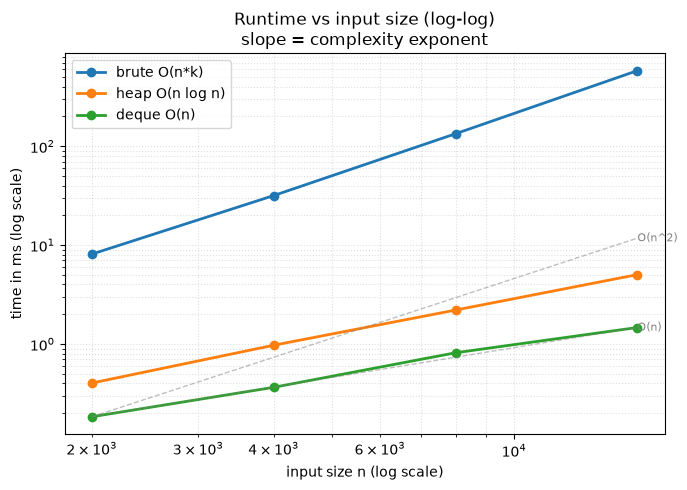

{'brute O(n*k)': [8.118459023535252,
  31.73012495972216,
  133.83508392143995,
  581.4750830177218],
 'heap O(n log n)': [0.4033340374007821,
  0.9724999545142055,
  2.20512505620718,
  5.035417038016021],
 'deque O(n)': [0.18395809456706047,
  0.36508298944681883,
  0.8159159915521741,
  1.469500013627112]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(n)), n // 2)      # increasing array, k = n/2
solutions = {
    "brute O(n*k)": max_sliding_window_brute,
    "heap O(n log n)": max_sliding_window_heap,
    "deque O(n)": max_sliding_window_deque,
}
sizes = [2000, 4000, 8000, 16000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Fixed Window](README.md) — the same one-in, one-out loop as every fixed window; the twist is the summary: a running max can't "subtract" the number that leaves, so a monotonic deque of indices keeps every candidate max in order.
- **Monotonic deque = "drop anything that can never win again":** an older value `<=` a newer one is dominated for the rest of its life; popping it keeps the deque decreasing and the max at the front.
- **Store indices, not values:** the index tells you when an element has left the window (`q[0] == r - k`).
- **Amortised O(1):** a step may pop many items, but each index is popped at most once over the whole run.
- **Heap with lazy deletion** is the safe fallback when you can't find the monotonic trick: `O(n log n)`, and it generalises to removals a deque can't handle.
- **Signal:** "maximum / minimum of every window of size `k`", "sliding window max/min", "for each subarray of length `k`".
- **Related problems:** Permutation in String (same fixed window, counts as the summary), Min Stack (track a max/min under removals), Daily Temperatures (monotonic stack, the one-ended cousin), Shortest Subarray with Sum at Least K (monotonic deque over prefix sums).
- **Common pitfalls:**
  1. Storing values instead of indices — then you can't tell when the front has left the window.
  2. Popping with `<` instead of `<=` is still correct but keeps duplicates; mixing up the direction (`>=`) builds an *increasing* deque and returns minimums.
  3. Recording before the window is full (`r < k - 1`).
  4. Calling it `O(n·k)` because of the inner `while` — count total pops, not pops per step.